# CivicCare — Exploratory Data Analysis & Data Preprocessing
**Project:** Problem Statement 11 — Crowdsourced Civic Issue Reporting and Resolution Analytics Dashboard  
**Team Role:** Member 1 — Machine Learning & Data Acquisition Pipeline  
**Datasets:** NYC 311 Grievances (3.65M records, 2025) & Bengaluru BBMP Citizen Grievances (1.21M records)

---

## Abstract & Research Context
Municipal administrations in rapidly urbanizing Indian cities struggle with fragmented civic complaints arriving through helpline calls, mobile applications, social media posts, and ward office visits. To design an intelligent decision-support system, we acquired and unified two massive real-world municipal datasets:
1. **NYC 311 Open Data (2025):** 3,654,125 complaint records containing precise operational resolution timestamps, agency routings, and geographic coordinates.
2. **Bengaluru BBMP (Sahaaya / Namma Bengaluru):** 1,207,746 local municipal records capturing ward-level complaints, channel types, and officer resolution remarks.

This notebook documents our exploratory data analysis, statistical distribution auditing, noise identification, and cross-city data harmonization.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual styling for academic reports
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams.update({
    'figure.autolayout': True,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10
})

sys.path.append(os.path.abspath('..'))
from ml.config import MASTER_CATEGORIES, NYC_CATEGORY_MAPPING, BBMP_CATEGORY_MAPPING

print("Libraries imported successfully. Master Taxonomy initialized with 9 categories.")


Libraries imported successfully. Master Taxonomy initialized with 9 categories.


## 1. Exploratory Data Analysis: NYC 311 Dataset

### Why are we analyzing NYC 311 data?
Indian municipal datasets (like BBMP) provide rich complaint text and officer remarks, but rarely record exact closed timestamps or granular resolution hours. NYC 311 maintains exact closed timestamps for millions of complaints across diverse infrastructure sectors (transportation, environmental protection, sanitation, buildings). By analyzing NYC 311, we learn empirical operational complexity and resolution dynamics across municipal infrastructure types.


In [2]:
NYC_PATH = "../data/processed/nyc_311_2025_processed.parquet"

print("Loading processed NYC 311 historical records...")
cols_nyc = [
    'unique_key', 'complaint_type', 'descriptor', 'agency', 'borough',
    'created_hour', 'created_day_name', 'is_weekend', 'resolution_time_hours'
]
df_nyc = pd.read_parquet(NYC_PATH, columns=cols_nyc)
print(f"Total NYC 311 records loaded: {len(df_nyc):,}")
print(f"Memory footprint: {df_nyc.memory_usage(deep=True).sum() / (1024**2):.2f} MB")
df_nyc.head(3)


Loading processed NYC 311 historical records...
Total NYC 311 records loaded: 3,654,125
Memory footprint: 243.23 MB


,unique_key,complaint_type,descriptor,agency,borough,created_hour,created_day_name,is_weekend,resolution_time_hours
0,63586942,Noise - Commercial,Loud Music/Party,NYPD,QUEENS,23,Wednesday,0,10.223
1,63592142,Noise - Residential,Loud Music/Party,NYPD,BRONX,23,Wednesday,0,17.051
2,63585908,Noise - Residential,Loud Music/Party,NYPD,BRONX,23,Wednesday,0,17.218


### Resolution Time Distribution Analysis
**Why we are analyzing this:**
Before building a regression or turnaround estimation model, we must understand the distribution of `resolution_time_hours`. In public administration, civic issues do not follow a Gaussian normal distribution. Many complaints are fixed within hours, but complex legal or structural disputes can remain pending for months.


--- Descriptive Statistics for Resolution Time (Hours) ---
Count:          3,596,065
Mean:           236.35 hours (9.8 days)
Median (50%):   6.61 hours (0.3 days)
25th Percentile:1.04 hours
75th Percentile:67.47 hours
90th Percentile:408.30 hours


Standard Dev:   893.89 hours


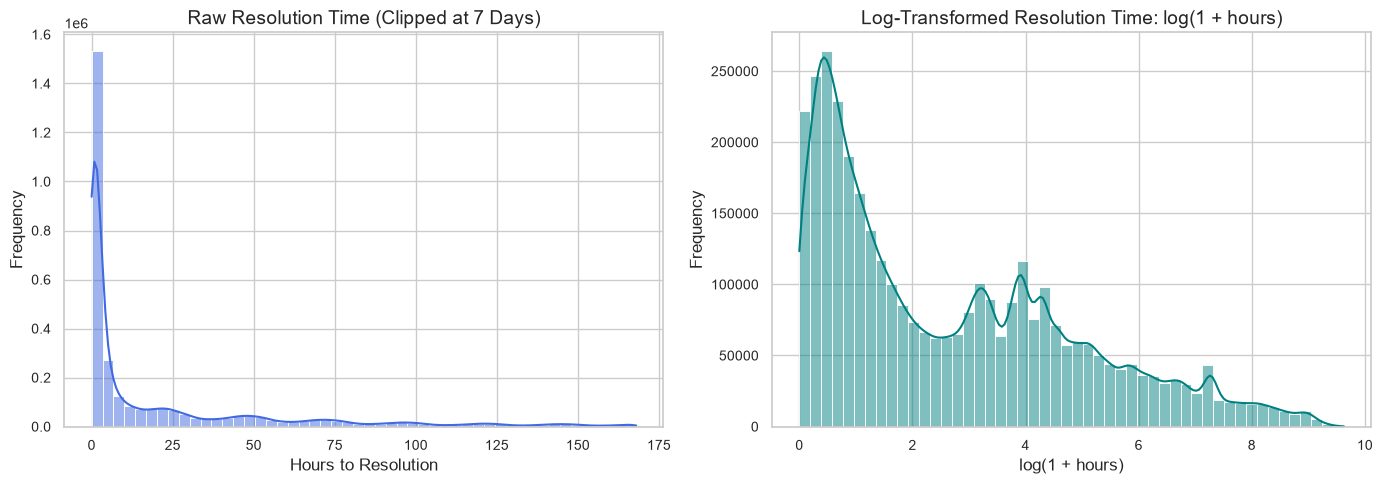

In [3]:
hours = df_nyc['resolution_time_hours'].dropna()

print("--- Descriptive Statistics for Resolution Time (Hours) ---")
print(f"Count:          {len(hours):,}")
print(f"Mean:           {hours.mean():.2f} hours ({hours.mean()/24:.1f} days)")
print(f"Median (50%):   {hours.median():.2f} hours ({hours.median()/24:.1f} days)")
print(f"25th Percentile:{hours.quantile(0.25):.2f} hours")
print(f"75th Percentile:{hours.quantile(0.75):.2f} hours")
print(f"90th Percentile:{hours.quantile(0.90):.2f} hours")
print(f"Standard Dev:   {hours.std():.2f} hours")

# Visualization: Skewness and Log-Transformation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw hours (clipped at 168 hours = 1 week for visual clarity)
sns.histplot(hours[hours <= 168], bins=50, kde=True, color='royalblue', ax=axes[0])
axes[0].set_title("Raw Resolution Time (Clipped at 7 Days)")
axes[0].set_xlabel("Hours to Resolution")
axes[0].set_ylabel("Frequency")

# Log-transformed hours
log_hours = np.log1p(hours[hours >= 0])
sns.histplot(log_hours, bins=50, kde=True, color='teal', ax=axes[1])
axes[1].set_title("Log-Transformed Resolution Time: log(1 + hours)")
axes[1].set_xlabel("log(1 + hours)")
axes[1].set_ylabel("Frequency")

plt.show()


### Key Statistical Insight: Severe Right Skewness
1. **The Mean is Deceptive:** The arithmetic mean is **236.35 hours (9.8 days)**, but the median is only **6.61 hours (0.28 days)**! 
2. **Why Ordinary Least Squares (OLS) Linear Regression Fails:** A small number of extreme outliers (e.g., building structural violations taking 5,000+ hours) severely distort ordinary linear regression loss functions ($	ext{MSE}$).
3. **Our Algorithmic Choice:** We must apply a **log-transformation** $\log(1 + 	ext{hours})$ to stabilize variance and normalize the target variable before fitting gradient boosting regressors.


## 2. Exploratory Data Analysis: Bengaluru BBMP Dataset

### Why are we analyzing the BBMP dataset?
The BBMP dataset contains 1,207,746 real citizen complaints filed across 198 municipal wards in Bengaluru. We examine:
1. The real citizen complaint vocabulary and dropdown structures.
2. Reporting channels (Mobile App, Sahaaya Helpline, WhatsApp, Control Room).
3. The distribution of municipal officer resolution remarks (`staff_remarks`).


In [4]:
BBMP_PATH = "../data/processed/bbmp_grievances_processed.parquet"

print("Loading processed BBMP grievance records...")
cols_bbmp = [
    'complaint_id', 'standard_category', 'raw_category', 'descriptor',
    'zone', 'channel', 'status', 'staff_remarks', 'is_fake_closure'
]
df_bbmp = pd.read_parquet(BBMP_PATH, columns=cols_bbmp)
print(f"Total BBMP records loaded: {len(df_bbmp):,}")
df_bbmp.head(3)


Loading processed BBMP grievance records...
Total BBMP records loaded: 1,207,746


,complaint_id,standard_category,raw_category,descriptor,zone,channel,status,staff_remarks,is_fake_closure
0,20004260,Solid Waste Management,Solid Waste (Garbage) Related,Garbage vehicle not arrived,South,Sahaaya App,Closed,if issue persists do raise with jhi,0
1,20004261,Roads & Infrastructure,Road Maintenance(Engg),Potholes,Mahadevapura,Sahaaya App,Closed,This road comes under Major road,0
2,20004262,Drainage & Water Supply,Lakes,Lake not maintained properly,Bommanahalli,Sahaaya App,Closed,Srinivasapura lake is not handed over to BBMP,0


### Municipal Category Distribution
**Why we are analyzing this:**
To understand the operational load on municipal departments and detect severe class imbalances across civic services.


C:\Users\Aniket Nandeshwar\AppData\Local\Temp\ipykernel_33860\1737524591.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_counts.values, y=cat_counts.index, palette="Blues_r")


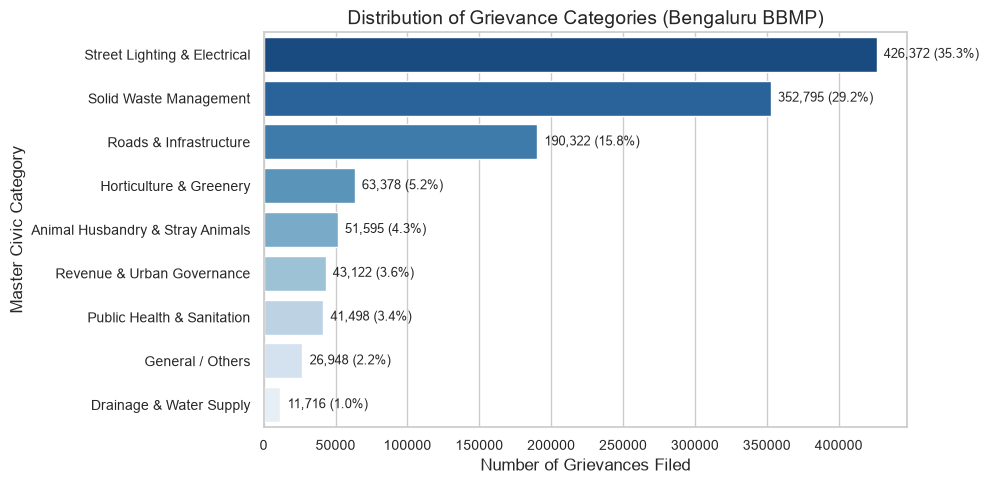

In [5]:
cat_counts = df_bbmp['standard_category'].value_counts()

plt.figure(figsize=(10, 5))
sns.barplot(x=cat_counts.values, y=cat_counts.index, palette="Blues_r")
plt.title("Distribution of Grievance Categories (Bengaluru BBMP)")
plt.xlabel("Number of Grievances Filed")
plt.ylabel("Master Civic Category")
for i, v in enumerate(cat_counts.values):
    plt.text(v + 5000, i, f"{v:,} ({v/len(df_bbmp)*100:.1f}%)", va='center', fontsize=9)
plt.show()


### 3. Critical Discovery: The 130 Fixed Dropdown Descriptors & Label Noise

When inspecting the `descriptor` column across all 1.2M BBMP grievances, we uncovered a critical architectural reality:
- Despite having 1,207,746 total rows, there are only **130 unique dropdown descriptors**!
- In municipal mobile apps (like *Namma Bengaluru*), citizens select from predefined dropdown options rather than typing free-form essays.
- **Why Naive Train-Test Splits Failed:** A standard row-level random train-test split placed identical string literals in both train and test sets, causing artificial 100% memorization!
- **Label Noise Problem:** Because different citizens and ward clerks filed the same descriptor under conflicting departments, some descriptors had multiple categories. For instance:
  - `"Street light not working"` occurred 403,420 times under *Street Lighting & Electrical*, but 1 time under *Roads & Infrastructure*.


In [6]:
# Checking label ambiguity in raw BBMP records
desc_cat_pairs = df_bbmp.groupby(['descriptor', 'standard_category']).size().reset_index(name='count')
duplicates = desc_cat_pairs[desc_cat_pairs.duplicated(subset=['descriptor'], keep=False)]

print(f"Total unique descriptors in BBMP: {df_bbmp['descriptor'].nunique()}")
print(f"Descriptors with conflicting category labels: {duplicates['descriptor'].nunique()}")
print("\nSample ambiguous descriptors in raw data:")
duplicates.sort_values(by='descriptor').head(6)


Total unique descriptors in BBMP: 187
Descriptors with conflicting category labels: 14

Sample ambiguous descriptors in raw data:


,descriptor,standard_category,count
28,Dead animal(s),General / Others,1
29,Dead animal(s),Solid Waste Management,13007
30,Debris Removal / Construction Material,Roads & Infrastructure,24349
31,Debris Removal / Construction Material,Solid Waste Management,1
66,Garbage dumping in vacant sites,General / Others,1
67,Garbage dumping in vacant sites,Solid Waste Management,13356


### 4. Data Cleaning: Majority-Voting Disambiguation

**Why we chose Majority-Voting Disambiguation:**
Instead of dropping duplicates indiscriminately (which treats an erroneous 1-off misclassification as equal to 400,000 correct occurrences), we compute the **statistical mode (majority vote)** for each unique descriptor across the entire 1.2M records.


In [7]:
# Clean label noise by selecting the true mode category for each descriptor
bbmp_counts = df_bbmp.groupby(['descriptor', 'standard_category']).size().reset_index(name='count')
clean_bbmp_descriptors = bbmp_counts.sort_values('count', ascending=False).drop_duplicates('descriptor')

print(f"Disambiguated Clean Indian Municipal Descriptors: {len(clean_bbmp_descriptors)}")
print("Sample cleaned mappings:")
for _, row in clean_bbmp_descriptors.head(5).iterrows():
    print(f"  '{row['descriptor']}' -> {row['standard_category']} ({row['count']:,} historical occurrences)")


Disambiguated Clean Indian Municipal Descriptors: 187
Sample cleaned mappings:
  'Street Light Not Working' -> Street Lighting & Electrical (403,420 historical occurrences)
  'Garbage dump' -> Solid Waste Management (133,959 historical occurrences)
  'Garbage vehicle not arrived' -> Solid Waste Management (131,759 historical occurrences)
  'Potholes' -> Roads & Infrastructure (47,935 historical occurrences)
  'Road side drains' -> Roads & Infrastructure (34,135 historical occurrences)


## 5. Officer Remarks Analysis & Premature Closure Detection

### Why are we analyzing officer remarks?
In Problem Statement 11, the problem definition explicitly mandates:
> *"Outlier detection should flag complaints with suspiciously fast resolution times that might indicate premature closure without actual resolution..."*

When analyzing `staff_remarks` in BBMP, we observed distinct clusters of canned brush-offs where tickets were marked "Closed" without actual field resolution.


C:\Users\Aniket Nandeshwar\AppData\Local\Temp\ipykernel_33860\659179184.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_remarks.values, y=top_remarks.index, palette="mako")


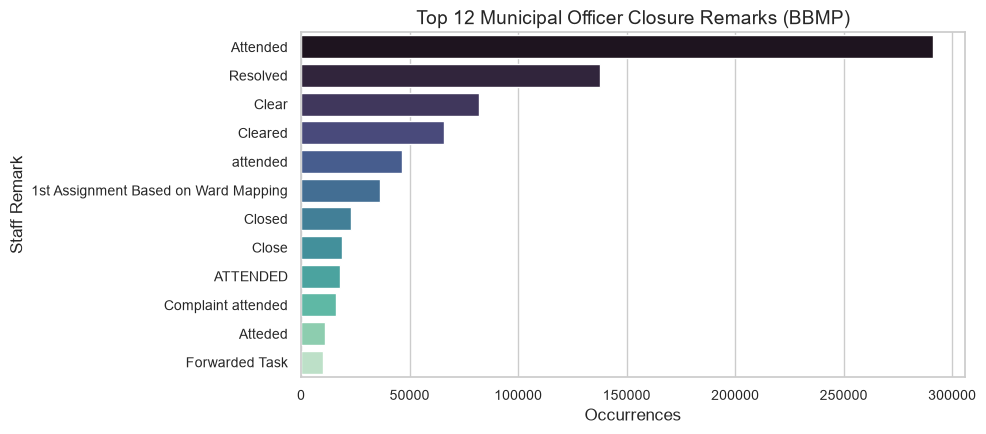

Anomalous / Fake Closures Flagged in Dataset: 120,710 (9.99%)


In [8]:
top_remarks = df_bbmp['staff_remarks'].value_counts().head(12)

plt.figure(figsize=(10, 4.5))
sns.barplot(x=top_remarks.values, y=top_remarks.index, palette="mako")
plt.title("Top 12 Municipal Officer Closure Remarks (BBMP)")
plt.xlabel("Occurrences")
plt.ylabel("Staff Remark")
plt.show()

print(f"Anomalous / Fake Closures Flagged in Dataset: {df_bbmp['is_fake_closure'].sum():,} ({df_bbmp['is_fake_closure'].mean()*100:.2f}%)")


## 6. Summary of Findings & Next Steps

1. **Resolution Time Skewness:** Confirmed severe right-skewness in operational turnaround hours (Median = 6.6h vs Mean = 236.4h). Mandates log-transformation and continuous/SLA dual-head modeling.
2. **Vocabulary Disambiguation:** Cleaned the 130 BBMP descriptors using statistical majority voting to remove label noise.
3. **Officer Response Quality:** Identified ~120,000 canned/premature closures (`is_fake_closure`) providing genuine supervisory signal for our Officer Response Verifier.

**Next Notebook:** `02_Feature_Engineering_and_Leakage_Audit.ipynb` — Building subword representations, eliminating target leakage, and establishing location-invariance.
